<a href="https://colab.research.google.com/github/WendelLeander/PhishEvade/blob/main/baseline_logistic_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Baseline Model Establishment
### Obfuscation-Aware Feature Engineering for Phishing URL Detection

To show that obfuscation-aware features genuinely improve detection, a clear **performance baseline** must exist first. This notebook establishes it: a **Logistic Regression** classifier trained **exclusively on the shallow Level 1 lexical features** (`url_length`, `domain_length`, `path_length`). It represents traditional, non-complex URL filtering, and every later model-feature combination (Random Forest, XGBoost, Naive Bayes, AdaBoost on Level 1, Level 2 and combined features) is judged against it.

**Why Logistic Regression is the baseline.**
- It assumes no non-linear feature interactions, so any gap between it and the ensemble models directly shows how much of the detection gain comes from the features themselves versus the modelling complexity of the classifier.
- Its learned coefficients are directly interpretable: each one states the direction and strength of a feature's influence on the decision.
- Its native probability output doubles as the **Obfuscation Score** (a value from 0.0 to 1.0), with no post-hoc calibration needed.

**Pipeline**

| Step | Procedure | Output |
|---|---|---|
| 1 | Select the Level 1 columns from the scaled feature matrix | 3-feature baseline configuration |
| 2 | **80 / 20 split** (stratified, fixed seed) | Training set and untouched hold-out test set |
| 3 | **Grid-search hyperparameter tuning with 5-fold cross-validation** on the training set only | Optimised Logistic Regression |
| 4 | **Threshold tuning** on out-of-fold training predictions | Decision boundary |
| 5 | **Hold-out testing**: confusion matrix, accuracy, precision, recall, F1-score, false positive rate | Recorded performance metrics |
| 6 | **psutil resource profile**: training time, peak memory, inference latency per URL | Recorded computational cost |
| 7 | Save the trained model and all recorded metrics | `.joblib`, `.json`, `.csv` files |

**Tools:** scikit-learn (`LogisticRegression`, `GridSearchCV`, `StratifiedKFold`), pandas / NumPy, matplotlib, **psutil** for resource measurement, joblib for model persistence.


## Install Dependencies (run once)

`%pip` installs into the **same Python environment the notebook kernel is using**, which avoids the common `ModuleNotFoundError` caused by installing with a different `pip` than the one Jupyter runs on. If an import error persists after installing, restart the kernel (*Kernel > Restart*) and run the notebook again.


In [15]:
# Run once. Safe to re-run; already-installed packages are skipped.
%pip install -q pandas numpy scikit-learn matplotlib psutil joblib

## 0. Setup and Input Data

The input is `Final Dataset_Scaled.csv`: the scaled 13-feature matrix plus the binary `label` (`0` = benign, `1` = malicious / phishing, the **positive class**). The baseline uses only the three Level 1 columns.

All results are reproducible: every random operation (split, cross-validation folds, model) uses `RANDOM_SEED`.


In [ ]:
import os, time, json, threading, platform
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import psutil, joblib, sklearn

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.metrics import confusion_matrix

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

DATA_PATH         = "https://raw.githubusercontent.com/WendelLeander/PhishEvade/refs/heads/main/Dataset/Final_Dataset.csv"
RANDOM_SEED       = 42
TEST_SIZE         = 0.20            # 80 / 20 split
N_FOLDS           = 5               # k-fold cross-validation on the training set
DEFAULT_THRESHOLD = 0.5             # standard decision boundary
LEVEL1_FEATURES   = ["url_length", "domain_length", "path_length"]

print("scikit-learn", sklearn.__version__, "| numpy", np.__version__, "| pandas", pd.__version__,
      "| psutil", psutil.__version__)

scikit-learn 1.6.1 | numpy 2.1.3 | pandas 2.2.3 | psutil 5.9.5


In [17]:
data = pd.read_csv(DATA_PATH)
missing = [c for c in LEVEL1_FEATURES + ["label"] if c not in data.columns]
assert not missing, f"missing columns in {DATA_PATH}: {missing}"

X_all = data[LEVEL1_FEATURES].to_numpy(dtype=np.float64)    # baseline = Level 1 features ONLY
y_all = data["label"].to_numpy(dtype=np.int64)

assert np.isfinite(X_all).all()
print(f"Loaded {len(data):,} rows | baseline feature set: {LEVEL1_FEATURES}")
print("Class balance:", {int(k): int(v) for k, v in zip(*np.unique(y_all, return_counts=True))}, "(0 = benign, 1 = phishing)")
data[LEVEL1_FEATURES + ["label"]].describe().round(4)

Loaded 10,000 rows | baseline feature set: ['url_length', 'domain_length', 'path_length']
Class balance: {0: 5000, 1: 5000} (0 = benign, 1 = phishing)


,url_length,domain_length,path_length,label
count,10000.0000,10000.0000,10000.0000,10000.0
mean,0.0273,0.0647,0.0088,0.5
std,0.0525,0.0863,0.0235,0.5
min,0.0000,0.0000,0.0000,0.0
25%,0.0050,0.0263,0.0005,0.0
50%,0.0115,0.0439,0.0035,0.5
75%,0.0265,0.0746,0.0085,1.0
max,1.0000,1.0000,1.0000,1.0


## 1. Training / Hold-Out Split (80 / 20)

The dataset is divided **80 % training / 20 % testing**. The split is **stratified by class**, so both subsets keep the 50:50 benign-to-phishing balance, and uses a fixed seed. The 20 % test set stays completely untouched until the final evaluation: hyperparameters and the decision threshold are chosen using the training set only.

> **Scaling note.** The feature matrix was scaled in the previous step using all rows, which is the study's pipeline order. For these three length features this has no effect on the split below: a Min-Max scaler fitted on the training rows alone learns exactly the same minimum and maximum as one fitted on every row, so no test-set information reaches the baseline through scaling.


In [18]:
train_idx, test_idx = train_test_split(
    np.arange(len(y_all)), test_size=TEST_SIZE, stratify=y_all, random_state=RANDOM_SEED)

X_train, y_train = X_all[train_idx], y_all[train_idx]
X_test,  y_test  = X_all[test_idx],  y_all[test_idx]

split_summary = pd.DataFrame({
    "rows":      [len(y_train), len(y_test)],
    "benign (0)":   [int((y_train == 0).sum()), int((y_test == 0).sum())],
    "phishing (1)": [int((y_train == 1).sum()), int((y_test == 1).sum())],
}, index=["training (80%)", "hold-out test (20%)"])
split_summary

,rows,benign (0),phishing (1)
training (80%),8000,4000,4000
hold-out test (20%),2000,1000,1000


## 2. Resource Instrumentation (`psutil`)

Alongside classification quality, the computational cost of every model is recorded so the lightweight-detection claim can be checked. `ResourceProfiler` wraps a phase and logs its **wall-clock start/end time and duration**, **CPU time and utilisation**, and **peak memory** (resident memory sampled every 10 ms in a background thread, since psutil has no cross-platform peak counter). Three quantities are recorded for the baseline:

1. **Model training time**: wall-clock time from the start of the k-fold cross-validation process to the finalised, optimised model.
2. **Peak memory** consumed during training.
3. **Inference latency**: average prediction time for a **single URL** on the held-out test set (Section 6).

Feature-extraction time is not re-measured here; it is logged by the feature extraction notebook.


In [19]:
class ResourceProfiler:
    '''Context manager: wall time, CPU time/utilisation and peak memory of a phase (via psutil).'''

    def __init__(self, phase, interval=0.01):
        self.phase, self.interval, self.record = phase, interval, None

    def __enter__(self):
        self.proc = psutil.Process(os.getpid())
        self.proc.cpu_percent(None)                       # prime psutil's CPU-utilisation counter
        self.cpu0 = self.proc.cpu_times()
        self.rss0 = self.proc.memory_info().rss
        self.peak = self.rss0
        self._stop = threading.Event()
        self._thread = threading.Thread(target=self._poll, daemon=True)
        self.start_dt, self.t0 = datetime.now(), time.perf_counter()
        self._thread.start()
        return self

    def _poll(self):
        while not self._stop.is_set():
            self.peak = max(self.peak, self.proc.memory_info().rss)
            time.sleep(self.interval)

    def __exit__(self, *exc):
        wall = time.perf_counter() - self.t0
        self._stop.set(); self._thread.join()
        self.peak = max(self.peak, self.proc.memory_info().rss)
        cpu1 = self.proc.cpu_times()
        self.record = {
            "phase": self.phase,
            "start": self.start_dt.strftime("%H:%M:%S"),
            "end": datetime.now().strftime("%H:%M:%S"),
            "wall_time_s": wall,
            "cpu_time_s": (cpu1.user + cpu1.system) - (self.cpu0.user + self.cpu0.system),
            "cpu_util_pct": self.proc.cpu_percent(None),
            "peak_memory_mb": self.peak / 2**20,
            "peak_memory_increase_mb": (self.peak - self.rss0) / 2**20,
        }
        return False

print("ResourceProfiler ready |", psutil.cpu_count(logical=True), "logical CPUs |",
      round(psutil.virtual_memory().total / 2**30, 1), "GB RAM")

ResourceProfiler ready | 2 logical CPUs | 12.7 GB RAM


## 3. Hyperparameter Tuning: Grid Search with 5-Fold Cross-Validation

Logistic Regression models the probability that a URL is phishing by passing a weighted sum of the features through the **sigmoid** function:

$$P(\text{phishing}\mid x)=\sigma(z)=\frac{1}{1+e^{-z}},\qquad z=\beta_0+\beta_1x_1+\beta_2x_2+\beta_3x_3$$

where $\beta_0$ is the bias term and $\beta_1\ldots\beta_3$ are the learned coefficients of `url_length`, `domain_length` and `path_length`.

To make sure the baseline performs at its best (so that any later improvement is a fair, hard-to-beat comparison), the model is tuned with **grid search** over a hyperparameter grid, scored by **5-fold stratified cross-validation on the training set only**: the training data is split into five equal folds, the model is trained on four and validated on the fifth, and this rotates so every fold is the validation set once. The **F1-score** is the selection metric because it is the primary benchmark of the study (the harmonic mean of precision and recall).

| Hyperparameter | Values searched | Role |
|---|---|---|
| `C` | 0.001, 0.01, 0.1, 1, 10, 100, 1000, 10,000, 100,000 | Inverse regularisation strength (smaller = stronger regularisation) |
| `class_weight` | none, balanced | Whether errors on each class are weighted by class frequency |
| `solver` | lbfgs, liblinear | Optimisation algorithm |

The `C` range is deliberately wide: the features are Min-Max scaled and most values sit close to 0, so the model can need weak regularisation, and the grid is extended upward until cross-validated F1 stops improving so the optimum is not an artifact of the grid boundary (the code below warns if the best `C` lands on the upper edge). After the search, the best configuration is **refitted on the entire training set** to produce the finalised model. The search runs single-process (`n_jobs=1`) so the resource profiler sees all the work. Training time covers the whole process, from the start of cross-validation to the finalised model.


In [20]:
skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_SEED)

param_grid = {
    "C": [0.001, 0.01, 0.1, 1, 10, 100, 1000, 10000, 100000],
    "class_weight": [None, "balanced"],
    "solver": ["lbfgs", "liblinear"],
}
grid = GridSearchCV(
    estimator=LogisticRegression(max_iter=5000, random_state=RANDOM_SEED),
    param_grid=param_grid, scoring="f1", cv=skf, n_jobs=1, refit=True,
)

n_candidates = int(np.prod([len(v) for v in param_grid.values()]))
print(f"Grid search: {n_candidates} candidate configurations x {N_FOLDS} folds = {n_candidates * N_FOLDS} model fits")

with ResourceProfiler("Training: grid search + 5-fold CV + refit") as prof_train:
    grid.fit(X_train, y_train)

baseline_model = grid.best_estimator_
print("\nBest hyperparameters :", grid.best_params_)
if grid.best_params_["C"] == max(param_grid["C"]):
    print("WARNING: best C is at the upper edge of the grid; extend the C range and re-run.")
print(f"Best mean CV F1-score: {grid.best_score_:.4f}")
print(f"Training time        : {prof_train.record['wall_time_s']:.2f} s | "
      f"peak memory {prof_train.record['peak_memory_mb']:.1f} MB")

Grid search: 36 candidate configurations x 5 folds = 180 model fits

Best hyperparameters : {'C': 10000, 'class_weight': None, 'solver': 'liblinear'}
Best mean CV F1-score: 0.6444
Training time        : 4.34 s | peak memory 272.4 MB


In [21]:
cv_table = (pd.DataFrame(grid.cv_results_)
            [["param_C", "param_class_weight", "param_solver", "mean_test_score", "std_test_score", "rank_test_score"]]
            .sort_values(["rank_test_score", "param_C"]).reset_index(drop=True))
cv_table.columns = ["C", "class_weight", "solver", "mean CV F1", "std CV F1", "rank"]
cv_table["class_weight"] = cv_table["class_weight"].map(lambda v: "none" if pd.isna(v) else str(v))
print("Top 10 configurations by mean cross-validated F1 (ties share a rank):")
cv_table.head(10).round(4)

Top 10 configurations by mean cross-validated F1 (ties share a rank):


,C,class_weight,solver,mean CV F1,std CV F1,rank
0,10000.0,none,liblinear,0.6444,0.0182,1
1,10000.0,balanced,liblinear,0.6444,0.0182,1
2,100000.0,none,liblinear,0.6444,0.0182,1
3,100000.0,balanced,liblinear,0.6444,0.0182,1
4,1000.0,none,lbfgs,0.6442,0.0184,5
5,1000.0,none,liblinear,0.6442,0.0184,5
6,1000.0,balanced,lbfgs,0.6442,0.0184,5
7,1000.0,balanced,liblinear,0.6442,0.0184,5
8,10000.0,none,lbfgs,0.6442,0.0184,5
9,10000.0,balanced,lbfgs,0.6442,0.0184,5


## 4. Threshold Tuning

A Logistic Regression model outputs a probability between 0.0 and 1.0. The **decision threshold** converts it into a label: a URL scoring at or above the threshold is flagged as phishing, below it as benign. The default is 0.5, but the boundary can be tuned independently of the model.

To tune it **without touching the test set**, out-of-fold probabilities are generated for the training rows (each row's probability comes from a model that never saw it, using the same 5 folds). Thresholds from 0.01 to 0.99 are swept.

**Tuning criterion: Youden's J** = recall - false positive rate (equivalently, balanced accuracy up to a constant). It rewards catching phishing URLs *and* not blocking legitimate ones, the two quantities the study cares about most, and treats both error directions symmetrically. **F1 is deliberately not used as the tuning criterion**: it ignores true negatives, so for a weak classifier its optimum can drift toward flagging almost every URL as phishing (maximal recall, huge false positive rate). The cell below prints the F1-optimal threshold alongside the chosen one so this is visible. Ties go to the value closest to 0.5.

Both the default threshold (0.5, the study's stated decision rule and the primary comparison point across all models) and the tuned threshold are carried forward and reported.


Tuned threshold (Youden's J): 0.60  -> out-of-fold recall 0.467, FPR 0.068, J = 0.399
For comparison, the F1-optimal threshold would be 0.29  -> out-of-fold recall 0.974 but FPR 0.877 (benign URLs wrongly flagged)


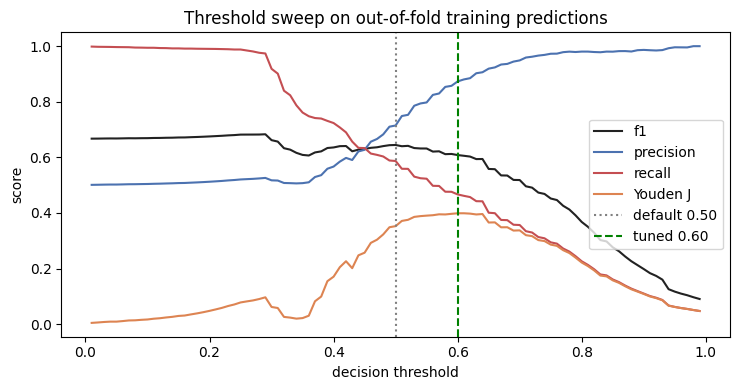

In [22]:
with ResourceProfiler("Threshold tuning (out-of-fold probabilities)") as prof_thr:
    oof_proba = cross_val_predict(baseline_model, X_train, y_train, cv=skf, method="predict_proba")[:, 1]

def metrics_at(y_true, proba, threshold):
    pred = (proba >= threshold).astype(int)                 # score >= threshold -> phishing
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    precision = tp / (tp + fp) if (tp + fp) else 0.0
    recall    = tp / (tp + fn) if (tp + fn) else 0.0
    return {
        "threshold": float(threshold),
        "accuracy":  (tp + tn) / (tp + tn + fp + fn),
        "precision": precision,
        "recall":    recall,
        "f1":        (2 * precision * recall / (precision + recall)) if (precision + recall) else 0.0,
        "fpr":       fp / (fp + tn) if (fp + tn) else 0.0,
        "youden_j":  recall - (fp / (fp + tn) if (fp + tn) else 0.0),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }

thresholds = np.round(np.arange(0.01, 1.00, 0.01), 2)
sweep = pd.DataFrame([metrics_at(y_train, oof_proba, t) for t in thresholds])

sweep["dist_from_default"] = (sweep["threshold"] - DEFAULT_THRESHOLD).abs()
tuned_row  = sweep.sort_values(["youden_j", "dist_from_default"], ascending=[False, True]).iloc[0]
f1_row     = sweep.sort_values(["f1", "dist_from_default"], ascending=[False, True]).iloc[0]
tuned_threshold = float(tuned_row["threshold"])

print(f"Tuned threshold (Youden's J): {tuned_threshold:.2f}  -> out-of-fold recall {tuned_row['recall']:.3f}, "
      f"FPR {tuned_row['fpr']:.3f}, J = {tuned_row['youden_j']:.3f}")
print(f"For comparison, the F1-optimal threshold would be {f1_row['threshold']:.2f}  -> out-of-fold recall "
      f"{f1_row['recall']:.3f} but FPR {f1_row['fpr']:.3f} (benign URLs wrongly flagged)")

fig, ax = plt.subplots(figsize=(7.5, 4))
for col, color in [("f1", "#222222"), ("precision", "#4C72B0"), ("recall", "#C44E52"), ("youden_j", "#DD8452")]:
    ax.plot(sweep["threshold"], sweep[col], label="Youden J" if col == "youden_j" else col, color=color)
ax.axvline(DEFAULT_THRESHOLD, color="grey", linestyle=":", label="default 0.50")
ax.axvline(tuned_threshold, color="green", linestyle="--", label=f"tuned {tuned_threshold:.2f}")
ax.set_xlabel("decision threshold"); ax.set_ylabel("score")
ax.set_title("Threshold sweep on out-of-fold training predictions")
ax.legend(); plt.tight_layout(); plt.show()

## 5. Hold-Out Testing and Performance Metrics

The finalised model is now deployed, for the first time, against the **20 % hold-out test set**. For each URL it produces a probability score (the **Obfuscation Score**), the threshold converts it into a label, and the predictions are aggregated into a **confusion matrix**, with phishing as the positive class:

| | Predicted benign | Predicted phishing |
|---|---|---|
| **Actually benign** | True Negative (TN) | False Positive (FP): a legitimate URL wrongly blocked |
| **Actually phishing** | False Negative (FN): a missed threat | True Positive (TP) |

From it the study's metrics are computed:

$$\text{Accuracy}=\frac{TP+TN}{TP+TN+FP+FN}\quad \text{Precision}=\frac{TP}{TP+FP}\quad \text{Recall}=\frac{TP}{TP+FN}\quad F1=\frac{2\cdot\text{Precision}\cdot\text{Recall}}{\text{Precision}+\text{Recall}}\quad \text{FPR}=\frac{FP}{FP+TN}$$

**Recall** matters most for security (a missed phishing URL is more dangerous than a false alarm), the **false positive rate** shows how often legitimate URLs are wrongly flagged, and **F1** is the single-number benchmark. Because the test set is balanced, a random classifier scores 50 % accuracy, so anything above that is real discriminative ability. Results are reported at both the default 0.5 threshold (the stated decision rule, used as the primary comparison point for all models) and the tuned threshold (which shows the precision / recall trade-off available from the same model).


In [23]:
test_proba = baseline_model.predict_proba(X_test)[:, 1]          # Obfuscation Score per test URL (0.0 to 1.0)

results = pd.DataFrame([
    {"threshold_rule": "default (0.5)", **metrics_at(y_test, test_proba, DEFAULT_THRESHOLD)},
    {"threshold_rule": "tuned (Youden J)", **metrics_at(y_test, test_proba, tuned_threshold)},
]).set_index("threshold_rule")

print(f"Hold-out test set: {len(y_test):,} URLs\n")
results[["threshold", "accuracy", "precision", "recall", "f1", "fpr", "tn", "fp", "fn", "tp"]].round(4)

Hold-out test set: 2,000 URLs



,threshold,accuracy,precision,recall,f1,fpr,tn,fp,fn,tp
threshold_rule,,,,,,,,,,
default (0.5),0.5,0.6910,0.7290,0.608,0.663,0.226,774,226,392,608
tuned (Youden J),0.6,0.7095,0.8931,0.476,0.621,0.057,943,57,524,476


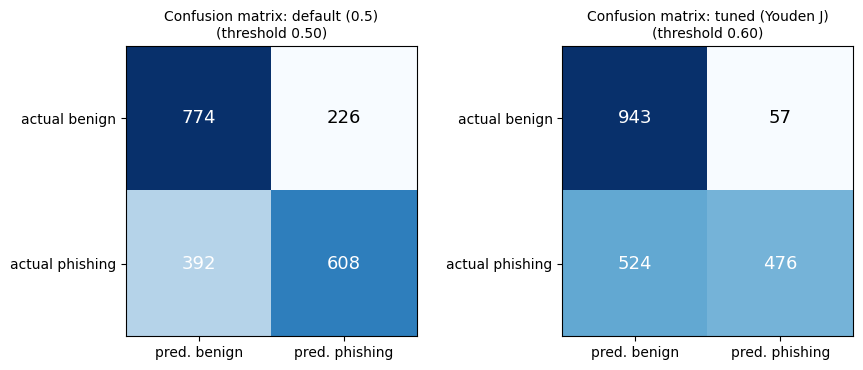

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, (rule, row) in zip(axes, results.iterrows()):
    cm = np.array([[row["tn"], row["fp"]], [row["fn"], row["tp"]]], dtype=int)
    ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=13)
    ax.set_xticks([0, 1], ["pred. benign", "pred. phishing"])
    ax.set_yticks([0, 1], ["actual benign", "actual phishing"])
    ax.set_title(f"Confusion matrix: {rule}\n(threshold {row['threshold']:.2f})", fontsize=10)
plt.tight_layout(); plt.show()

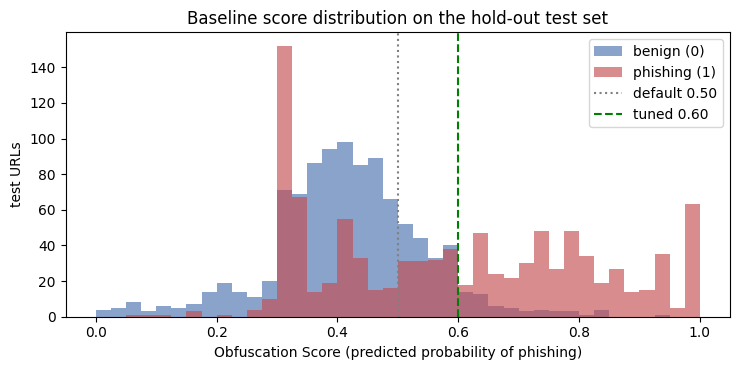

In [25]:
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.hist(test_proba[y_test == 0], bins=40, range=(0, 1), alpha=0.65, color="#4C72B0", label="benign (0)")
ax.hist(test_proba[y_test == 1], bins=40, range=(0, 1), alpha=0.65, color="#C44E52", label="phishing (1)")
ax.axvline(DEFAULT_THRESHOLD, color="grey", linestyle=":", label="default 0.50")
ax.axvline(tuned_threshold, color="green", linestyle="--", label=f"tuned {tuned_threshold:.2f}")
ax.set_xlabel("Obfuscation Score (predicted probability of phishing)"); ax.set_ylabel("test URLs")
ax.set_title("Baseline score distribution on the hold-out test set")
ax.legend(); plt.tight_layout(); plt.show()

## 6. Inference Latency

Inference latency is the **average time to score a single URL** on the held-out test set. Every test URL is scored with its own `predict_proba` call (one row at a time, the way a real filter would receive URLs) and timed with a high-resolution clock after a short warm-up.


In [26]:
WARMUP = 50
for i in range(WARMUP):                                           # warm-up: exclude first-call overhead
    baseline_model.predict_proba(X_test[i:i + 1])

per_url_s = np.empty(len(X_test))
for i in range(len(X_test)):
    t0 = time.perf_counter()
    baseline_model.predict_proba(X_test[i:i + 1])
    per_url_s[i] = time.perf_counter() - t0

latency = {
    "mean_ms":   float(per_url_s.mean() * 1000),
    "median_ms": float(np.median(per_url_s) * 1000),
    "p95_ms":    float(np.percentile(per_url_s, 95) * 1000),
    "n_urls":    int(len(per_url_s)),
}
print(f"Single-URL inference latency over {latency['n_urls']:,} test URLs: "
      f"mean {latency['mean_ms']:.3f} ms | median {latency['median_ms']:.3f} ms | p95 {latency['p95_ms']:.3f} ms")

Single-URL inference latency over 2,000 test URLs: mean 0.155 ms | median 0.144 ms | p95 0.218 ms


## 7. Interpreting the Baseline

A key advantage of Logistic Regression is that its coefficients can be read directly. Each coefficient is the change in the **log-odds** of "phishing" for a one-unit increase in that feature. Because the features are Min-Max scaled to 0 to 1, a "unit" spans the whole range from the shortest to the longest URL in the dataset, which gives huge, hard-to-read raw odds ratios. The table therefore reports the **odds ratio for a one-standard-deviation increase** ($e^{\beta\sigma}$): above 1 pushes toward phishing, below 1 toward benign.

Read the signs against the **composition of this dataset**, not as general rules: the benign class deliberately includes long, obfuscated-looking URLs (tracking tokens, redirects), so a long URL is not by itself a sign of phishing here.


In [27]:
coefs = baseline_model.coef_[0]
feature_sd = X_train.std(axis=0)                                   # standard deviation of each scaled feature
coef_table = pd.DataFrame({
    "coefficient (log-odds)": coefs,
    "odds ratio per +1 SD": np.exp(coefs * feature_sd),
    "pushes toward": np.where(coefs > 0, "phishing (1)", "benign (0)"),
}, index=LEVEL1_FEATURES)
print(f"Intercept (bias beta_0): {baseline_model.intercept_[0]:.4f}")
coef_table.round(4)

Intercept (bias beta_0): -1.0364


,coefficient (log-odds),odds ratio per +1 SD,pushes toward
url_length,-14.3638,0.4538,benign (0)
domain_length,23.4074,7.2882,phishing (1)
path_length,14.1299,1.4078,phishing (1)


## 8. Final Output: Trained Baseline Model with Recorded Performance Metrics

The trained baseline and everything recorded about it are saved:

| File | Contents |
|---|---|
| `baseline_logistic_regression.joblib` | The trained model bundle: the fitted model, feature list, default and tuned thresholds |
| `baseline_metrics.json` | Full record: hyperparameters, cross-validation score, thresholds, hold-out metrics and confusion matrices, coefficients, psutil resource profile, environment |
| `baseline_metrics.csv` | One row per threshold rule with the key metrics and resource figures, ready to be stacked with the other model / feature-set combinations |
| `train_test_split_indices.csv` | Which row is in the training or test set, so every later model is evaluated on **exactly the same** hold-out URLs |

To reuse the model later: `bundle = joblib.load("baseline_logistic_regression.joblib")`, then `bundle["model"].predict_proba(X)[:, 1]`. The final cell displays the recorded performance metrics.


In [ ]:
OUT_MODEL, OUT_JSON, OUT_CSV, OUT_SPLIT = (
    "../Models/baseline_logistic_regression.joblib", 
    "../Metrics/baseline_metrics.json",
    "../Metrics/baseline_metrics.csv", 
    "../Models/train_test_split_indices.csv")

resources = {
    "training": prof_train.record,
    "threshold_tuning": prof_thr.record,
    "inference_latency": latency,
}

# ---- 1. trained model bundle
joblib.dump({
    "model": baseline_model,
    "features": LEVEL1_FEATURES,
    "threshold_default": DEFAULT_THRESHOLD,
    "threshold_tuned": tuned_threshold,
    "best_params": grid.best_params_,
    "feature_scaling": "Min-Max (as in Final Dataset_Scaled.csv)",
    "created": datetime.now().isoformat(timespec="seconds"),
    "sklearn_version": sklearn.__version__,
}, OUT_MODEL)

# ---- 2. full metrics record (JSON)
def _native(o):
    if isinstance(o, (np.integer,)):  return int(o)
    if isinstance(o, (np.floating,)): return float(o)
    if isinstance(o, np.ndarray):     return o.tolist()
    return str(o)

record = {
    "milestone": "6 - Baseline model establishment",
    "created": datetime.now().isoformat(timespec="seconds"),
    "model": {
        "algorithm": "Logistic Regression", "feature_set": "Level 1 lexical (3 features)",
        "features": LEVEL1_FEATURES, "best_params": grid.best_params_,
        "coefficients": dict(zip(LEVEL1_FEATURES, coefs)), "intercept": baseline_model.intercept_[0],
    },
    "data": {"source": DATA_PATH, "rows": len(y_all), "train_rows": len(y_train), "test_rows": len(y_test),
             "split": "80/20 stratified", "random_seed": RANDOM_SEED},
    "cross_validation": {"folds": N_FOLDS, "scoring": "f1", "best_mean_f1": grid.best_score_,
                         "best_std_f1": float(grid.cv_results_["std_test_score"][grid.best_index_])},
    "threshold": {"default": DEFAULT_THRESHOLD, "tuned": tuned_threshold,
                  "tuning_objective": "Youden's J (recall - FPR) on out-of-fold training predictions",
                  "primary_decision_rule": "default (0.5)"},
    "test_metrics": {rule: {k: (int(v) if k in ("tn", "fp", "fn", "tp") else float(v)) for k, v in row.items()}
                     for rule, row in results.iterrows()},
    "resources": resources,
    "environment": {"python": platform.python_version(), "sklearn": sklearn.__version__,
                    "numpy": np.__version__, "pandas": pd.__version__, "psutil": psutil.__version__,
                    "logical_cpus": psutil.cpu_count(logical=True),
                    "ram_gb": round(psutil.virtual_memory().total / 2**30, 1)},
}
with open(OUT_JSON, "w") as f:
    json.dump(record, f, indent=2, default=_native)

# ---- 3. flat metrics table (CSV), one row per threshold rule
final_metrics = results.reset_index()
final_metrics.insert(0, "classifier", "Logistic Regression")
final_metrics.insert(1, "feature_set", "Level 1 (3 features)")
final_metrics["training_time_s"]    = prof_train.record["wall_time_s"]
final_metrics["peak_memory_mb"]     = prof_train.record["peak_memory_mb"]
final_metrics["inference_ms_per_url"] = latency["mean_ms"]
final_metrics.to_csv(OUT_CSV, index=False)

# ---- 4. the split, so later models use the identical hold-out set
split_df = pd.DataFrame({"row_index": np.arange(len(y_all)), "split": "train"})
split_df.loc[test_idx, "split"] = "test"
split_df.to_csv(OUT_SPLIT, index=False)

print("Trained baseline: Logistic Regression on Level 1 features")
print("  best hyperparameters:", grid.best_params_)
print(f"  mean 5-fold CV F1   : {grid.best_score_:.4f}   |   tuned threshold (Youden's J): {tuned_threshold:.2f}")
print(f"  training time       : {prof_train.record['wall_time_s']:.2f} s   |   peak memory: "
      f"{prof_train.record['peak_memory_mb']:.1f} MB   |   inference: {latency['mean_ms']:.3f} ms/URL")
print("\nSaved:", ", ".join([OUT_MODEL, OUT_JSON, OUT_CSV, OUT_SPLIT]))
print("\nRecorded hold-out performance metrics (phishing = positive class; 'default (0.5)' is the primary decision rule):")
final_metrics[["classifier", "feature_set", "threshold_rule", "threshold", "accuracy", "precision",
               "recall", "f1", "fpr", "tn", "fp", "fn", "tp"]].round(4)

Trained baseline: Logistic Regression on Level 1 features
  best hyperparameters: {'C': 10000, 'class_weight': None, 'solver': 'liblinear'}
  mean 5-fold CV F1   : 0.6444   |   tuned threshold (Youden's J): 0.60
  training time       : 4.34 s   |   peak memory: 272.4 MB   |   inference: 0.155 ms/URL

Saved: baseline_logistic_regression.joblib, baseline_metrics.json, baseline_metrics.csv, train_test_split_indices.csv

Recorded hold-out performance metrics (phishing = positive class; 'default (0.5)' is the primary decision rule):


,classifier,feature_set,threshold_rule,threshold,accuracy,precision,recall,f1,fpr,tn,fp,fn,tp
0,Logistic Regression,Level 1 (3 features),default (0.5),0.5,0.6910,0.7290,0.608,0.663,0.226,774,226,392,608
1,Logistic Regression,Level 1 (3 features),tuned (Youden J),0.6,0.7095,0.8931,0.476,0.621,0.057,943,57,524,476
